# Summary: tokenization and depth in learning SAT solving by next-token prediction

Two token encodings of the same task (learn to reproduce a DPLL unit-propagation/
backtracking solver via next-token prediction) were tried this investigation:

- **v1 -- full-state-snapshot** (`spin_gnn/ksat.py`, `sat_transformer.py`): every step
  re-emits the *entire* current clause database as a real-valued vector token.
- **v2 -- event-based reasoning trace** (`spin_gnn/ksat2.py`, `sat_transformer2.py`):
  only *events* (which single variable got set/unset, and why) as categorical tokens
  into a 12-token-plus-variables-plus-clauses vocabulary.

This notebook summarizes every experiment run against both, with citations to the
exact checkpoint/sweep files backing each number. **No new experiments were run for
this summary** -- every figure below reads data already on `$SCRATCH` from prior runs.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

SCRATCH = Path(os.environ["SCRATCH"]) / "spin_gnn"
INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])
    ax.xaxis.label.set_color(INK["secondary"])
    ax.yaxis.label.set_color(INK["secondary"])

## Experiment log (citations)

| # | Experiment | Config | Result | Source |
|---|---|---|---|---|
| 1 | v1 `(d_model,nhead)` sweep | `d=256,h=8` best | 94.25% acc, 0% completion | `sat_hparam_sweep/d0256_h08*` |
| 2 | v1 nhead-only follow-up | `d=256`, h in 1..32 | only h>=16 ever solved (0.7-1.4%) despite worse accuracy | `sat_hparam_sweep/sweep_d0256_h16.csv`, `h32.csv` |
| 3 | v1 depth/MLP-width sweep | `L` in 1,2,4,6 x `ff` in 256..2048 | best `L=4,ff=1024` (94.3% acc); `L=6,ff>=1024` **best_epoch=0 (total training failure)** | `sat_hparam_sweep/sweep_d0256_h08_L06_ff01024.csv` |
| 4 | v1 low-rank Q/K (`qk_dim`) sweep | h in 1..16 x `qk_dim` in 64..512 | **overall v1 best**: `h=16,qk_dim=512` -> 94.40% acc, 1.4% completion | `sat_hparam_sweep/d0256_h16_L04_ff01024_qk0512/config.json` |
| 5 | `copy_vs_delta_breakdown` diagnostic on #4's model | teacher-forced, split by token role | copying an **already-decided** variable: 34.0% (near chance); copying a **still-unassigned** one: 96.0% | `copy_vs_delta-41775939.out` |
| 6 | v2 first hyperparameter+LR sweep (72 configs) | `n_vars=16,alpha=1.25` (m=20 clauses), d/h/L/lr grid | best **solve_rate=6.7%** at `d=128,h=2,L=2,lr=3e-4` | `sat2_hparam_sweep/aggregated.csv` |
| 7 | v2 depth scan, post-norm | `L` in 1..16 x lr in {3e-4,1e-3}, `d=128,h=2` | best 7.0% (`L=16,lr=3e-4`); **`L in {12,16}` at `lr=1e-3` totally collapsed (0% well-formed)** | `sweep_m020_h02_L12.csv`, `L16.csv` |
| 8 | v2 depth scan, pre-norm (`norm_first=True`) | same grid + `L=24` | collapse fixed everywhere (>=99.3% well-formed); **new best 12.3%** (`L=16,lr=3e-4`); `L=24` did not beat `L=16` | `sweep_m020_h02_L16_pre.csv` |
| 9 | v2 head-count scan at #8's optimum | h in {1,2,4,8,16,32}, `L=16,lr=3e-4,` pre-norm | best region h=1-2 (~4-5%); monotonic-ish decline past h=4; **repeat run at h=2 landed at 4.0% vs #8's 12.3%** (noise) | `sweep_m020_h*_L16_pre.csv` |
| 10 | `step accuracy` diagnostic on #8's model | teacher-forced, by grammatical role | lowest: **which var to backtrack on (35%, n=40)**, **which var to decide on (42%, n=2057)**; value/step-type/clause-ref all >=72%, most >=96% | `sat2_step_acc-46383261.out` |


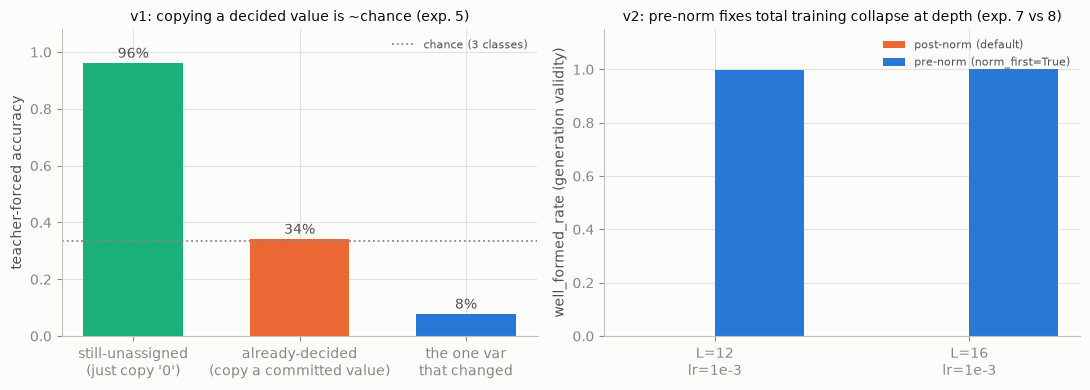

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.patch.set_facecolor(INK["surface"])

# Panel A: experiment 5 -- v1's redundant-copy encoding makes even COPYING fail.
labels_a = ["still-unassigned\n(just copy '0')", "already-decided\n(copy a committed value)", "the one var\nthat changed"]
vals_a = [0.96, 0.34, 0.0764]
bars = axes[0].bar(labels_a, vals_a, color=[CATEGORICAL[2], CATEGORICAL[1], CATEGORICAL[0]], width=0.6)
axes[0].axhline(1/3, color=INK["muted"], linestyle=":", lw=1.3, label="chance (3 classes)")
for b, v in zip(bars, vals_a):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", color=INK["secondary"])
axes[0].set_ylim(0, 1.08)
axes[0].set_ylabel("teacher-forced accuracy")
axes[0].set_title("v1: copying a decided value is ~chance (exp. 5)", color=INK["primary"], fontsize=10)
axes[0].legend(frameon=False, labelcolor=INK["secondary"], fontsize=8)
style_axis(axes[0])

# Panel B: experiments 7 vs 8 -- post-norm collapse at depth, fixed by pre-norm.
layers = ["L=12\nlr=1e-3", "L=16\nlr=1e-3"]
post = [0.0, 0.0]        # well_formed_rate, post-norm (total collapse)
pre = [0.997, 1.0]       # well_formed_rate, pre-norm
x = np.arange(len(layers))
w = 0.35
axes[1].bar(x - w/2, post, w, color=CATEGORICAL[1], label="post-norm (default)")
axes[1].bar(x + w/2, pre, w, color=CATEGORICAL[0], label="pre-norm (norm_first=True)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(layers)
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("well_formed_rate (generation validity)")
axes[1].set_title("v2: pre-norm fixes total training collapse at depth (exp. 7 vs 8)", color=INK["primary"], fontsize=10)
axes[1].legend(frameon=False, labelcolor=INK["secondary"], fontsize=8)
style_axis(axes[1])

fig.tight_layout()
plt.show()

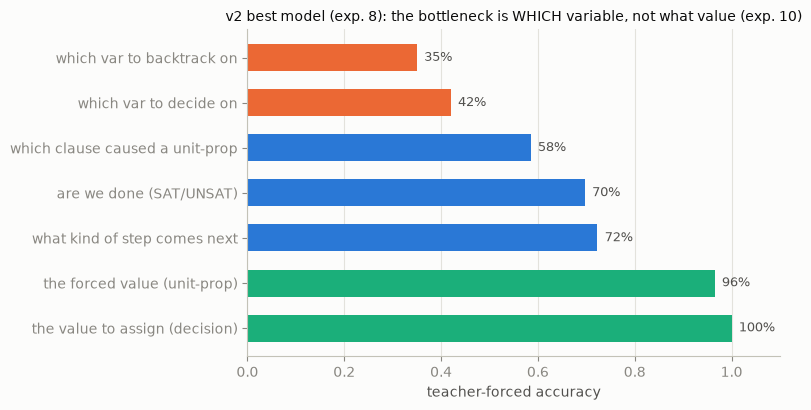

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
fig.patch.set_facecolor(INK["surface"])

roles = [
    ("which var to backtrack on", 0.350, 40),
    ("which var to decide on", 0.420, 2057),
    ("which clause caused a unit-prop", 0.585, 1493),
    ("are we done (SAT/UNSAT)", 0.697, 300),
    ("what kind of step comes next", 0.723, 3590),
    ("the forced value (unit-prop)", 0.965, 1493),
    ("the value to assign (decision)", 1.000, 2057),
]
labels = [r[0] for r in roles][::-1]
vals = [r[1] for r in roles][::-1]
colors = [CATEGORICAL[1] if v < 0.5 else (CATEGORICAL[0] if v < 0.9 else CATEGORICAL[2]) for v in vals]
bars = ax.barh(labels, vals, color=colors, height=0.6)
for b, v in zip(bars, vals):
    ax.text(v + 0.015, b.get_y() + b.get_height() / 2, f"{v:.0%}", va="center", color=INK["secondary"], fontsize=9)
ax.set_xlim(0, 1.1)
ax.set_xlabel("teacher-forced accuracy")
ax.set_title("v2 best model (exp. 8): the bottleneck is WHICH variable, not what value (exp. 10)",
             color=INK["primary"], fontsize=10)
style_axis(ax)
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## Takeaways

**1. Tokenization choice dominated everything else tried.** v1's redundant
full-clause-snapshot encoding capped out near 1.4% real completion no matter how much
architecture was tuned (experiments 1-4) -- because it forced the model to *re-copy*
the entire clause state at every step, and that copying itself turned out to be
barely above chance for already-decided variables (34%, exp. 5), not just the harder
reasoning. Switching to v2's event-based encoding (same underlying DPLL algorithm, far
shorter sequences, no redundant re-statement) didn't just help marginally -- it changed
which failure mode even shows up. No v1 config ever approached v2's eventual 12.3%
solve_rate (exp. 8), and v2 reached strong SAT/UNSAT-call accuracy within 10 epochs in
early smoke testing, something v1 never did at any epoch count. **The encoding was a
bigger lever than any hyperparameter in either sweep.**

**2. Depth ( = MLP-block depth, since each transformer layer is one attention + one
MLP sublayer) genuinely helps, but only once optimization is set up to allow it.** Both
encodings hit the *same* wall at depth: v1's `num_layers=6` sweep point failed to train
at all (`best_epoch=0`, exp. 3) and v2's `num_layers in {12,16}` at `lr=1e-3` collapsed
identically (0% well-formed, exp. 7) -- both are the textbook post-norm-at-depth
instability. v1's instance was never revisited, but fixing it in v2 via pre-norm
(`norm_first=True`, exp. 8) didn't just stop the collapse -- it nearly doubled the best
result (7.0%->12.3%). **The apparent depth "ceiling" in exp. 7 was partly an
optimization artifact, not a true capacity limit** -- worth remembering before reading
any depth sweep's numbers at face value when post-norm is the default.

**3. Head count was never the lever, in either encoding.** v1's dedicated nhead sweep
(exp. 2) and v2's sweep at its best depth (exp. 9) both show the same shape: a small
head count (1-2) is as good as or better than many heads, unlike depth's clear
monotonic-ish trend.

**4. Run-to-run noise is large at this scale** -- an identical config landed at 4.0%
and 12.3% solve_rate on two different seeds (exp. 9) -- so single-run comparisons
smaller than roughly 2x should not be over-trusted; several sweep conclusions here
(e.g. the exact best head count) are directional, not precise.

**5. Even the best model's bottleneck is combinatorial selection, not value prediction
or bookkeeping** (exp. 10) -- it almost always gets the *value* right once it has
committed to a variable (96-100%), but picking *which* variable to act on is barely
better than chance (35-42%). This is a different kind of problem than tokenization or
depth can directly fix, and was the motivation for the (currently paused, not yet
retrained) `[SATISFIED]`/`[REACTIVATED]` clause-status annotation proposal.